In [1]:
import pandas as pd
import numpy as np

# Walmart Sales Analysis

**Goal:** Understand what drives Walmart's weekly sales across 45 stores, and prepare the data for a dashboard.

**Data:** 6,435 rows × 8 columns, weekly sales per store, Feb 2010 to Oct 2012
(Store, Date, Weekly_Sales, Holiday_Flag, Temperature, Fuel_Price, CPI, Unemployment)

**Tools:** Excel (cleaning) → Python (EDA) → Power BI / Tableau (dashboard)

**Questions answered:**
1. Is the data clean and reliable?
2. How do sales change over time and by month?
3. Do holidays increase sales?
4. Do weather and economic factors affect sales?
5. Which stores perform best and worst?

In [2]:
#Dataset import
data=pd.read_csv(r"C:\Users\NITHYASHREE S\Documents\Walmart.csv")
data

,Store,Date,Weekly_Sales,Holiday_Flag,Temperature,Fuel_Price,CPI,Unemployment
0,1,2010-02-05,1643690.90,0,42.31,2.572,211.096358,8.106
1,1,2010-02-12,1641957.44,1,38.51,2.548,211.242170,8.106
2,1,2010-02-19,1611968.17,0,39.93,2.514,211.289143,8.106
3,1,2010-02-26,1409727.59,0,46.63,2.561,211.319643,8.106
4,1,2010-03-05,1554806.68,0,46.50,2.625,211.350143,8.106
...,...,...,...,...,...,...,...,...
6430,45,2012-09-28,713173.95,0,64.88,3.997,192.013558,8.684
6431,45,2012-10-05,733455.07,0,64.89,3.985,192.170412,8.667
6432,45,2012-10-12,734464.36,0,54.47,4.000,192.327265,8.667
6433,45,2012-10-19,718125.53,0,56.47,3.969,192.330854,8.667


## Step 0: Data validation
**Why:** Check the data is trustworthy before analysing it.
**Checks:** data types, missing values, duplicates, date range, negative sales, store count.
**Result:** 0 missing values, 0 duplicates, 0 negative sales, 45 stores, dates from 2010-02-05 to 2012-10-26. The data is clean.

In [3]:
#Data validation checks
# Import the libraries we need
import pandas as pd                # for working with tables (dataframes)
import matplotlib.pyplot as plt    # for drawing charts
import seaborn as sns              # for nicer statistical charts

# Convert the Date column from text to a real date type
# format="%Y-%m-%d" means year-month-day, like 2010-02-05
data["Date"] = pd.to_datetime(data["Date"], format="%Y-%m-%d")

# Show the number of rows, column names, data types and non-null counts
data.info()

# Count the missing (empty) values in each column. Expected: 0
print("\nMissing values:\n", data.isnull().sum())

# Count fully duplicated rows. Expected: 0
print("\nDuplicates:", data.duplicated().sum())

# Show the first and last dates, to confirm the time period covered
print("\nDate range:", data["Date"].min(), "to", data["Date"].max())

# Summary statistics of sales: count, average, spread, minimum, quartiles, maximum
print("\n", data["Weekly_Sales"].describe())

# Count rows with negative sales (sales can't be below zero). Expected: 0
print("Negative sales:", (data["Weekly_Sales"] < 0).sum())

# List the distinct values in Holiday_Flag. Expected: only 0 and 1
print("Holiday_Flag values:", data["Holiday_Flag"].unique())

# Count the distinct stores and show the lowest and highest store number. Expected: 45 stores, 1 to 45
print("Stores:", data["Store"].nunique(), "| range:", data["Store"].min(), "to", data["Store"].max())

<class 'pandas.DataFrame'>
RangeIndex: 6435 entries, 0 to 6434
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   Store         6435 non-null   int64         
 1   Date          6435 non-null   datetime64[us]
 2   Weekly_Sales  6435 non-null   float64       
 3   Holiday_Flag  6435 non-null   int64         
 4   Temperature   6435 non-null   float64       
 5   Fuel_Price    6435 non-null   float64       
 6   CPI           6435 non-null   float64       
 7   Unemployment  6435 non-null   float64       
dtypes: datetime64[us](1), float64(5), int64(2)
memory usage: 402.3 KB

Missing values:
 Store           0
Date            0
Weekly_Sales    0
Holiday_Flag    0
Temperature     0
Fuel_Price      0
CPI             0
Unemployment    0
dtype: int64

Duplicates: 0

Date range: 2010-02-05 00:00:00 to 2012-10-26 00:00:00

 count    6.435000e+03
mean     1.046965e+06
std      5.643666e+05
min      2.099862e+0

## Step 1: Total weekly sales trend
**Why:** See the overall direction of sales and any repeating spikes.
**Finding:** [one line after you look at your chart, for example the spikes around year-end]

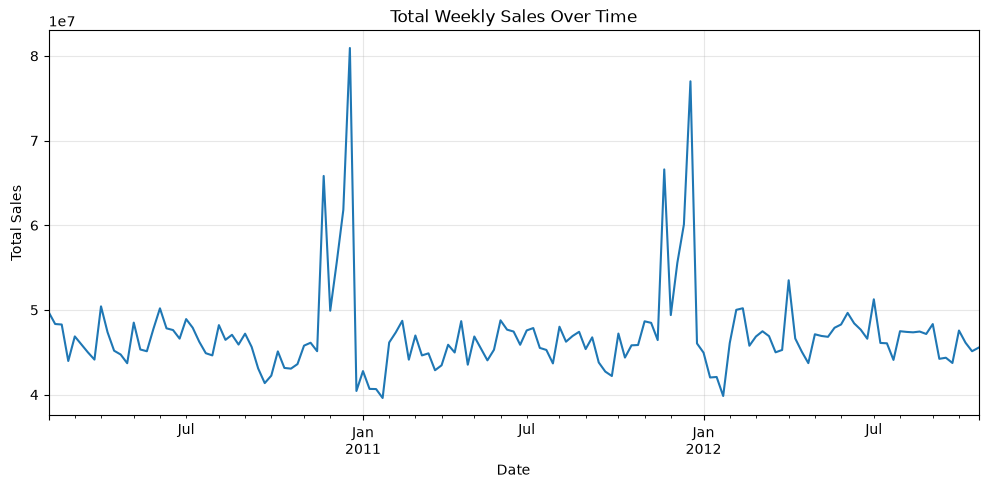

In [4]:
#Total weekly sales trend
# Add up the sales of all 45 stores for each date
weekly = data.groupby("Date")["Weekly_Sales"].sum()

# Set the chart size (width 12, height 5)
plt.figure(figsize=(12, 5))

# Draw the line chart (Date on x-axis, total sales on y-axis)
weekly.plot()

# Add the title and axis labels so anyone can read the chart
plt.title("Total Weekly Sales Over Time")
plt.xlabel("Date")
plt.ylabel("Total Sales")

# Light grid lines to make the values easier to read
plt.grid(alpha=0.3)

# Display the chart
plt.show()

## Step 2: Holiday vs non-holiday weeks
**Why:** Test whether holiday weeks really sell more.
**Finding:** Holiday weeks have only a slightly higher median than normal weeks, and the boxes overlap heavily. The flag alone is a weak signal.

Holiday_Flag
0    1.041256e+06
1    1.122888e+06
Name: Weekly_Sales, dtype: float64


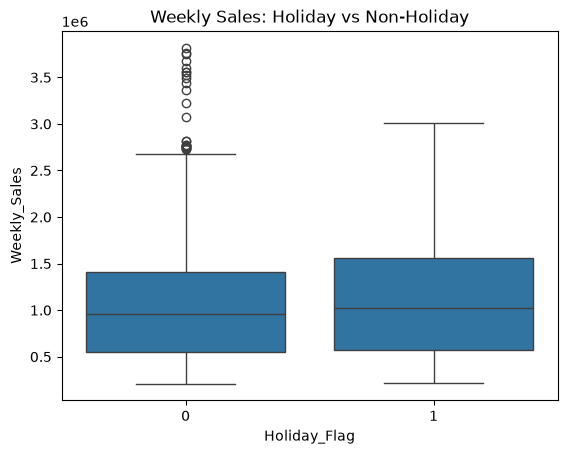

In [5]:
#Holiday vs. non-holiday sales
# Average weekly sales for normal weeks (0) and holiday weeks (1)
print(data.groupby("Holiday_Flag")["Weekly_Sales"].mean())

# Box plot: shows the middle value, the spread, and the extreme (outlier) weeks for each group
sns.boxplot(x="Holiday_Flag", y="Weekly_Sales", data=data)

# Title for the chart
plt.title("Weekly Sales: Holiday vs Non-Holiday")

# Display the chart
plt.show()

## Step 3: Monthly seasonality
**Why:** Find the strongest and weakest months.
**Finding:** December is the strongest month and January the weakest.
**Note:** Nov, Dec and Jan have only 2 years of data (the data ends in Oct 2012), and monthly totals are affected by the number of weeks in a month.

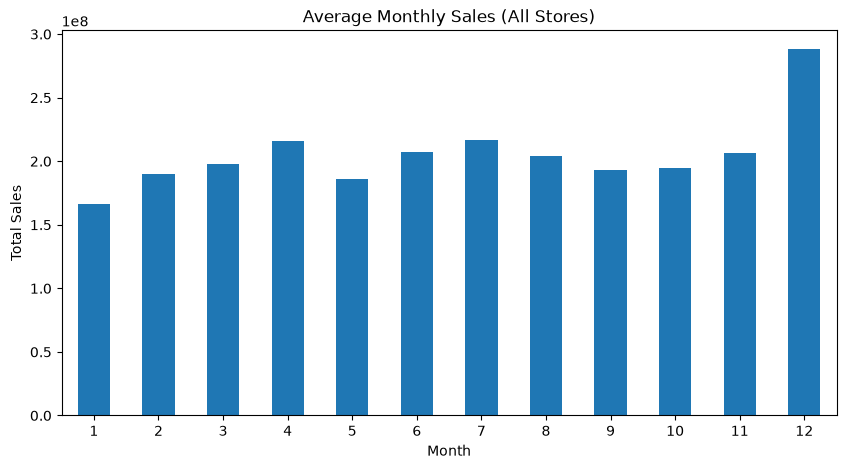

In [6]:
#Monthly seasonality
# Create a Year column by taking the year part of each date (2010, 2011, 2012)
data["Year"] = data["Date"].dt.year

# Create a Month column by taking the month number of each date (1 = Jan ... 12 = Dec)
data["Month"] = data["Date"].dt.month

# Add up the sales of all stores for each Year and Month combination
# reset_index() turns the result back into a normal table
monthly = data.groupby(["Year", "Month"])["Weekly_Sales"].sum().reset_index()

# Now average those monthly totals across the years, so each month (1 to 12) has one value
month_avg = monthly.groupby("Month")["Weekly_Sales"].mean()

# Set the chart size (width 10, height 5)
plt.figure(figsize=(10, 5))

# Draw the bar chart: one bar per month
month_avg.plot(kind="bar")

# Add the title and axis labels so anyone can read the chart
plt.title("Average Monthly Sales (All Stores)")
plt.xlabel("Month")
plt.ylabel("Total Sales")

# Keep the month numbers horizontal so they are easy to read
plt.xticks(rotation=0)

# Display the chart
plt.show()

## Step 4: Top 10 sales weeks
**Why:** Check whether the biggest weeks are the flagged holiday weeks.
**Finding:** 8 of the top 10 weeks are in Nov or Dec. The two biggest are the weeks before Christmas, which are **not** flagged as holidays. Only 2 of the 10 (Thanksgiving weeks) are flagged.

In [7]:
#Top 10 sales weeks and the holiday flag
# Group the data by Date, so we get one row per week
# agg() lets us calculate two things at once for each week:
#   Total_Sales  = sum of the sales of all 45 stores
#   Holiday_Flag = 1 if that week is a holiday week, else 0
week_totals = data.groupby("Date").agg(
    Total_Sales=("Weekly_Sales", "sum"),
    Holiday_Flag=("Holiday_Flag", "max")
)

# Sort from highest to lowest sales and show only the top 10 rows
print(week_totals.sort_values("Total_Sales", ascending=False).head(10))

            Total_Sales  Holiday_Flag
Date                                 
2010-12-24  80931415.60             0
2011-12-23  76998241.31             0
2011-11-25  66593605.26             1
2010-11-26  65821003.24             1
2010-12-17  61820799.85             0
2011-12-16  60085695.94             0
2010-12-10  55666770.39             0
2011-12-09  55561147.70             0
2012-04-06  53502315.87             0
2012-07-06  51253021.88             0


## Step 5: Correlation analysis
**Why:** Check whether temperature, fuel price, CPI, unemployment or the holiday flag move with sales.
**Finding:** All correlations with weekly sales are weak (between -0.11 and +0.04). None of these factors explains sales on its own.
**Caution:** Correlation does not prove cause.

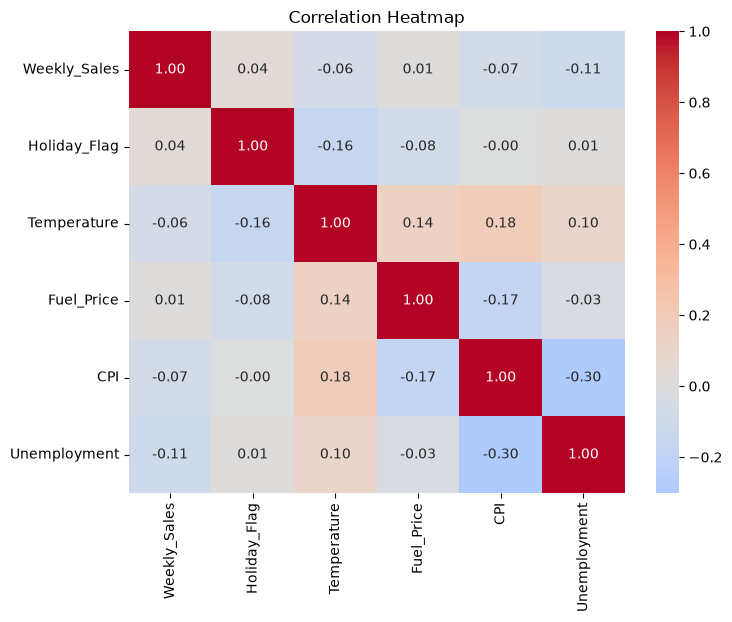

In [8]:
#Correlations
# Pick only the numeric columns we want to compare with sales
cols = ["Weekly_Sales", "Holiday_Flag", "Temperature", "Fuel_Price", "CPI", "Unemployment"]

# Calculate the correlation between every pair of these columns
corr = data[cols].corr()

# Set the chart size
plt.figure(figsize=(8, 6))

# Draw the heatmap: annot=True prints the numbers, cmap sets the colour scheme
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0)

# Add a title and display
plt.title("Correlation Heatmap")
plt.show()

## Step 6: Outlier detection
**Method:** IQR rule (values beyond 1.5 × IQR from the quartiles).
**Finding:** 34 outliers: 9 in November and 25 in December, none in other months.
**Decision:** Kept them. They are real peak-season sales, not data errors.

In [9]:
#Outliers
# 25th and 75th percentile of weekly sales
q1 = data["Weekly_Sales"].quantile(0.25)
q3 = data["Weekly_Sales"].quantile(0.75)

# IQR = the range covered by the middle 50% of the data
iqr = q3 - q1

# Upper and lower limits: beyond these, a value counts as an outlier
lower = q1 - 1.5 * iqr
upper = q3 + 1.5 * iqr

# Pick the rows outside the limits
outliers = data[(data["Weekly_Sales"] < lower) | (data["Weekly_Sales"] > upper)]

# How many outliers, and which dates do they fall on?
print("Number of outliers:", len(outliers))
print(outliers["Date"].dt.month.value_counts().sort_index())

Number of outliers: 34
Date
11     9
12    25
Name: count, dtype: int64


## Step 7: Store performance
**Why:** Find top and bottom stores.
**Finding:** Store 20 and Store 4 lead at about 2.1M per week. Store 33 is lowest at about 0.26M. The best store sells roughly 8 times the worst, so **store** is the biggest driver of sales.

Top 5:
 Store
20    2.107677e+06
4     2.094713e+06
14    2.020978e+06
13    2.003620e+06
2     1.925751e+06
Name: Weekly_Sales, dtype: float64

Bottom 5:
 Store
38    385731.653287
36    373511.992797
5     318011.810490
44    302748.866014
33    259861.692028
Name: Weekly_Sales, dtype: float64


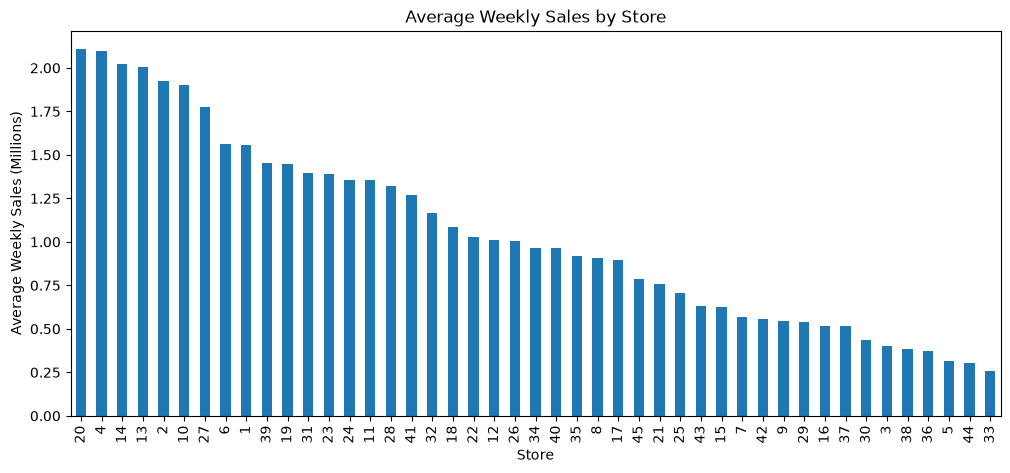

In [10]:
#Store performance
# Average weekly sales for each store, sorted from highest to lowest
store_avg = data.groupby("Store")["Weekly_Sales"].mean().sort_values(ascending=False)

# Show the top 5 and bottom 5 stores
print("Top 5:\n", store_avg.head(5))
print("\nBottom 5:\n", store_avg.tail(5))

# Bar chart of all 45 stores (in millions)
plt.figure(figsize=(12, 5))
(store_avg / 1e6).plot(kind="bar")
plt.title("Average Weekly Sales by Store")
plt.xlabel("Store")
plt.ylabel("Average Weekly Sales (Millions)")
plt.show()

## Summary of key findings
1. Data is clean: 0 missing values and 0 duplicates.
2. Sales peak in December, and 8 of the top 10 weeks are in Nov or Dec.
3. The biggest weeks are just before Christmas and are not flagged as holidays.
4. Temperature, fuel price, CPI and unemployment show weak correlation with sales.
5. Store matters most: the top store sells about 8× the bottom store.

## Recommendations
- Plan stock and staffing around the pre-Christmas and Thanksgiving weeks, not only the flagged weeks.
- Use a custom "Peak Season" label in the dashboard.
- Review the lowest-performing stores (33, 44, 5).

## Limitations
- Data covers Feb 2010 to Oct 2012, so Nov, Dec and Jan have only 2 years.
- Correlation does not show cause.